INSTALL PACKAGES FOR GRAPH OPERATIONS

In [ ]:
# V5e1 TPU IS USED FOR THE GRAPH DATA PRECOMPUTATION

In [ ]:
!pip install torch==2.4.0
!pip install torch_geometric
!pip install  dgl -f https://data.dgl.ai/wheels/torch-2.4/repo.html
!pip install numpy==1.24.4
!pip install rdkit
!pip install graphein[extras]

Looking in links: https://data.dgl.ai/wheels/torch-2.4/repo.html
  Using cached numpy-1.24.4.tar.gz (10.9 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
import os
import sys
import torch
import rdkit
import torch
import logging
import numpy as np
import pandas as pd
import networkx as nx
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import random
import graphein.molecule as gm
from rdkit import RDLogger
from torch_geometric.data import Data
from utils.graph_generator import run_graph_generator  # make sure the utils folder is found in your current directory before running this impoprt script

IMPORT AChE LABEL DATASET RETRIEVED FROM (Vignaux et al., 2023)

In [ ]:
m1 = pd.read_csv("/content/drive/MyDrive/thesis/others/Human_dataset_1micromolar.csv")
ex = pd.read_csv("/content/drive/MyDrive/thesis/others/Extended_human_dataset_100micromolar.csv")

In [ ]:
m1

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1
...,...,...
4070,CCN(CP(=O)(O)O)CP(=O)(O)O,0
4071,NCCCC(O)(P(=O)(O)O)P(=O)(O)O,0
4072,CN(CP(=O)(O)O)CP(=O)(O)O,0
4073,O=P(O)(O)CN1CCCN(CP(=O)(O)O)CC1,0


In [ ]:
ex

,SMILES,single-class-label
0,C[n+]1ccccc1/C=N/O,0
1,NC(=O)c1cc[n+](COC[n+]2ccccc2/C=N/O)cc1,0
2,CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C,1
3,Nc1c2c(nc3ccccc13)CCCC2,1
4,CCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(CC)C1C2,1
...,...,...
10377,CCN(C)C(=O)OC1CCCN(Cc2ccccc2)C1,0
10378,CC(C)c1ccc(NC(=O)OC2CCCN(Cc3ccccc3)C2)cc1,0
10379,CCN(C)C(=O)OCC1CCN(C2Cc3ccccc3C2)CC1,0
10380,C#CCN1CCC(COC(=O)N(C)CC)CC1,0


In [ ]:
# GET THE MINIMUM AND THE MAXIMUM NODES IN THE DATASETS

# M1

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices = []
index_of_nodes_less_than_or_equal_to_51_m1 = []

for i, smile in tqdm(enumerate(m1['SMILES']), total=len(m1['SMILES']), desc="Computing graphs and collecting node counts in m1 dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
        if num_nodes <= 51:
            index_of_nodes_less_than_or_equal_to_51_m1.append(i)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes = min(num_nodes_list)
max_nodes = max(num_nodes_list)


Computing graphs and collecting node counts in m1 dataset: 100%|██████████| 4075/4075 [00:13<00:00, 310.13it/s]


In [ ]:
print(f"Maximum number of nodes in m1 dataset: {max_nodes}")
print(f"Minimum number of nodes in m1 dataset: {min_nodes}")
print(f"Number of molecule indices in m1 dataset with errors: {len(error_indices)}")

Maximum number of nodes in m1 dataset: 77
Minimum number of nodes in m1 dataset: 9
Number of molecule indices in m1 dataset with errors: 0


In [ ]:
# Now we can extract the molecules with not more than 51 nodes. This is required to be compatible with the pretrained model
m1 = m1.iloc[index_of_nodes_less_than_or_equal_to_51_m1]
m1

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1
...,...,...
4070,CCN(CP(=O)(O)O)CP(=O)(O)O,0
4071,NCCCC(O)(P(=O)(O)O)P(=O)(O)O,0
4072,CN(CP(=O)(O)O)CP(=O)(O)O,0
4073,O=P(O)(O)CN1CCCN(CP(=O)(O)O)CC1,0


In [ ]:
m1 = m1.reset_index(drop=True)
m1

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1
...,...,...
3996,CCN(CP(=O)(O)O)CP(=O)(O)O,0
3997,NCCCC(O)(P(=O)(O)O)P(=O)(O)O,0
3998,CN(CP(=O)(O)O)CP(=O)(O)O,0
3999,O=P(O)(O)CN1CCCN(CP(=O)(O)O)CC1,0


In [ ]:
# GET THE MINIMUM AND THE MAXIMUM NODES IN THE DATASETS

# EX

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)
RDLogger.DisableLog('rdApp.*')

config = gm.MoleculeGraphConfig()

num_nodes_list = []
error_indices_ = []
index_of_nodes_less_than_or_equal_to_51_ex = []

for i, smile in tqdm(enumerate(ex['SMILES']), total=len(ex['SMILES']), desc="Computing graphs and collecting node counts in ex dataset"):
    try:
        graph = gm.construct_graph(smiles=smile, config=config)
        num_nodes = graph.number_of_nodes()
        num_nodes_list.append(num_nodes)
        if num_nodes <= 51:
            index_of_nodes_less_than_or_equal_to_51_ex.append(i)
    except Exception as e:
        logger.error(f"Error at index {i}")
        error_indices.append(i)
        continue

min_nodes_ = min(num_nodes_list)
max_nodes_ = max(num_nodes_list)

Computing graphs and collecting node counts in ex dataset: 100%|██████████| 10382/10382 [00:14<00:00, 736.31it/s] 


In [ ]:
print(f"Maximum number of nodes in ex dataset: {max_nodes_}")
print(f"Minimum number of nodes in ex dataset: {min_nodes_}")
print(f"Number of molecule indices in ex dataset with errors: {len(error_indices_)}")

Maximum number of nodes in ex dataset: 90
Minimum number of nodes in ex dataset: 2
Number of molecule indices in ex dataset with errors: 0


In [ ]:
# MINIMUM NODE IS 2 AND MAXIMUM NODE IS 90

In [ ]:
# Now we can extract the molecules with not more than 51 nodes. This is required to be compatible with the pretrained model
ex = ex.iloc[index_of_nodes_less_than_or_equal_to_51_ex]
ex

,SMILES,single-class-label
0,C[n+]1ccccc1/C=N/O,0
1,NC(=O)c1cc[n+](COC[n+]2ccccc2/C=N/O)cc1,0
2,CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C,1
3,Nc1c2c(nc3ccccc13)CCCC2,1
4,CCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(CC)C1C2,1
...,...,...
10377,CCN(C)C(=O)OC1CCCN(Cc2ccccc2)C1,0
10378,CC(C)c1ccc(NC(=O)OC2CCCN(Cc3ccccc3)C2)cc1,0
10379,CCN(C)C(=O)OCC1CCN(C2Cc3ccccc3C2)CC1,0
10380,C#CCN1CCC(COC(=O)N(C)CC)CC1,0


In [ ]:
ex = ex.reset_index(drop=True)
ex

,SMILES,single-class-label
0,C[n+]1ccccc1/C=N/O,0
1,NC(=O)c1cc[n+](COC[n+]2ccccc2/C=N/O)cc1,0
2,CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C,1
3,Nc1c2c(nc3ccccc13)CCCC2,1
4,CCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(CC)C1C2,1
...,...,...
10273,CCN(C)C(=O)OC1CCCN(Cc2ccccc2)C1,0
10274,CC(C)c1ccc(NC(=O)OC2CCCN(Cc3ccccc3)C2)cc1,0
10275,CCN(C)C(=O)OCC1CCN(C2Cc3ccccc3C2)CC1,0
10276,C#CCN1CCC(COC(=O)N(C)CC)CC1,0


In [ ]:
m = m1[["SMILES", "single-class-label"]]
m

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1
...,...,...
3996,CCN(CP(=O)(O)O)CP(=O)(O)O,0
3997,NCCCC(O)(P(=O)(O)O)P(=O)(O)O,0
3998,CN(CP(=O)(O)O)CP(=O)(O)O,0
3999,O=P(O)(O)CN1CCCN(CP(=O)(O)O)CC1,0


In [ ]:
e = ex[["SMILES", "single-class-label"]]
e

,SMILES,single-class-label
0,C[n+]1ccccc1/C=N/O,0
1,NC(=O)c1cc[n+](COC[n+]2ccccc2/C=N/O)cc1,0
2,CNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(C)[C@@H]1N2C,1
3,Nc1c2c(nc3ccccc13)CCCC2,1
4,CCCCCCNC(=O)Oc1ccc2c(c1)[C@]1(C)CCN(CC)C1C2,1
...,...,...
10273,CCN(C)C(=O)OC1CCCN(Cc2ccccc2)C1,0
10274,CC(C)c1ccc(NC(=O)OC2CCCN(Cc3ccccc3)C2)cc1,0
10275,CCN(C)C(=O)OCC1CCN(C2Cc3ccccc3C2)CC1,0
10276,C#CCN1CCC(COC(=O)N(C)CC)CC1,0


In [ ]:
print(m["single-class-label"].value_counts())
print(e["single-class-label"].value_counts())

single-class-label
0    2228
1    1773
Name: count, dtype: int64
single-class-label
0    6785
1    3493
Name: count, dtype: int64


In [ ]:
# get actives in datasets

m_actives = m[m["single-class-label"] == 1]
e_actives = e[e["single-class-label"] == 1]


# and the inactives

m_inactives = m[m["single-class-label"] == 0]
e_inactives = e[e["single-class-label"] == 0]

In [ ]:
print(m_inactives.count())
print(e_inactives.count())
print(m_actives.count())
print(e_actives.count())

SMILES                2228
single-class-label    2228
dtype: int64
SMILES                6785
single-class-label    6785
dtype: int64
SMILES                1773
single-class-label    1773
dtype: int64
SMILES                3493
single-class-label    3493
dtype: int64


In [ ]:
t_act = pd.concat([m_actives, e_actives]).reset_index(drop=True)
t_inact = pd.concat([m_inactives, e_inactives]).reset_index(drop=True)

In [ ]:
t_act.head()

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1


In [ ]:
t_inact.head()

,SMILES,single-class-label
0,C#CCN[C@H]1CCc2ccccc21,0
1,COc1ccc2c3c1O[C@H]1C[C@@H](O)C=C[C@@]31CCN(C)C2,0
2,O=C(CCc1c[nH]c2ccccc12)NCCC1CCN(Cc2ccccc2)CC1,0
3,Cc1c(C)c2c(c(C)c1O)CCC(C)(C(=O)NCCNc1c3c(nc4cc...,0
4,CN(C)C(=O)Oc1ccc[n+](C)c1,0


In [ ]:
print(t_act.duplicated(subset=["SMILES"]).sum())
print(t_inact.duplicated(subset=["SMILES"]).sum())

1766
425


In [ ]:
t_actives = t_act.drop_duplicates(subset=["SMILES"])
t_inactives = t_inact.drop_duplicates(subset=["SMILES"])

In [ ]:
print(t_actives.count())
print(t_inactives.count())

SMILES                3500
single-class-label    3500
dtype: int64
SMILES                8588
single-class-label    8588
dtype: int64


In [ ]:
t_conc = pd.concat([t_actives, t_inactives]).reset_index(drop=True)
t_conc.head()

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1


In [ ]:
print(t_conc.duplicated(subset=["SMILES"]).sum())

1551


In [ ]:
t_conc = t_conc.drop_duplicates(subset=["SMILES"], keep=False)
t_conc

,SMILES,single-class-label
0,CN(C)C(=O)Oc1cccc([N+](C)(C)C)c1,1
1,O=C(CCCCC1CCSS1)NCCCNc1c2c(nc3cc(Cl)ccc13)CCCC2,1
2,COc1cc2c(cc1OC)C(=O)C(CC1CCN(CCCNc3c4c(nc5cc(C...,1
3,CNC(=O)Oc1cccc(CN(C)CCCOc2ccc3c(=O)c4ccccc4oc3...,1
4,CCC1=CC2Cc3nc4cc(Cl)ccc4c(N)c3[C@@H](C1)C2,1
...,...,...
12083,C[As+](C)(C)CC(=O)O,0
12084,CCc1cccc(CC)c1N(COC)C(=O)CS(=O)(=O)O,0
12085,CCCC(O)C(O)CO,0
12086,C[C@@]1(c2nccc3cc4c(cc23)OCO4)Oc2ccc3c(c2O1)OCO3,0


In [ ]:
print(t_conc["single-class-label"].value_counts())

single-class-label
0    7037
1    1949
Name: count, dtype: int64


In [ ]:
# lets perform random selection to balance out the dataset

random.seed(42)

class_counts = t_conc["single-class-label"].value_counts()
minority_class_count = class_counts[1]

t_conc_minority = t_conc[t_conc["single-class-label"] == 1]
t_conc_majority = t_conc[t_conc["single-class-label"] == 0]

# Undersample the majority class

t_majority_undersampled = t_conc_majority.sample(n=minority_class_count, random_state=42)

# Combine the undersampled majority class with the minority class

t_balanced = pd.concat([t_majority_undersampled, t_conc_minority])

t = t_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
t

,SMILES,single-class-label
0,COc1ccc(C(=O)CCC2C=CN(Cc3cccc(Cl)c3)C=C2C#N)cc1OC,1
1,C=C(C)C(=O)OCC,0
2,Cc1ccc(-c2nc(NC(=O)C3CCN(Cc4cccc(F)c4)CC3)sc2-...,0
3,c1ccc(CN2CCC(CCc3nccc4ccccc34)CC2)cc1,1
4,C=C1c2cccc(O)c2C(=O)C2=C(O)[C@]3(O)C(=O)C(C(N)...,0
...,...,...
3893,Nc1ccc(C=Cc2ccc(N)cc2S(=O)(=O)O)c(S(=O)(=O)O)c1,0
3894,CCCCCCCCBr,0
3895,CN(CCCCCOc1ccc(-c2cc3ccccc3o2)cc1)Cc1ccccc1,0
3896,COc1ccc(-c2nc(NC(=O)C3CCN(Cc4cccc(F)c4)CC3)sc2...,1


In [ ]:
print(t["single-class-label"].value_counts())

single-class-label
1    1949
0    1949
Name: count, dtype: int64


In [ ]:
# now lets split this randomly into train and external validation in 90:10

m, e = train_test_split(t, test_size=0.1, random_state=42)

In [ ]:
m

,SMILES,single-class-label
1650,BrCCCCBr,0
1904,COC(=O)c1ccc(C)cc1,0
2473,COc1cccc(CCCCCCc2cccc(OC)[n+]2C)[n+]1C,1
1987,CCCNC(C)C(=O)Nc1ccccc1C,0
279,COc1cc(C=O)ccc1OC(=O)C(C)C,0
...,...,...
1130,CC(=O)CCl,0
1294,Nc1ccc(S(=O)(=O)NC(=O)c2ccccc2)cc1,0
860,CCN(CCCCCCOCCCCCCCCOCCCCCCN(CC)Cc1ccccc1OC)Cc1...,1
3507,CCN(CCCCCCNC1=CC(=O)C(NCCCCCCN(CC)Cc2ccccc2Cl)...,1


In [ ]:
e

,SMILES,single-class-label
3685,COc1cccc2c1C=[N+](c1ccc(C#N)cc1)CC2,0
912,O=[N+]([O-])c1cncn1CCN1CCOCC1,0
321,CCOc1ccc(NC(C)=O)cc1N,0
2098,Cc1cccc2nc3c(c(N)c12)CCCC3,1
1480,CC1=CC2Cc3nc4ccccc4c(NCCCCCCCCCCCCNc4c5c(nc6cc...,1
...,...,...
881,S=C(NNc1c2c(nc3ccccc13)CCCC2)Nc1ccccc1,1
1204,CCCC[N+](=O)[O-],0
251,Cc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CCOC1N2C,1
3525,CC(C)CC(=O)CC(C)CC(C)C,0


In [ ]:
print(m["single-class-label"].value_counts())
print(e["single-class-label"].value_counts())

single-class-label
1    1755
0    1753
Name: count, dtype: int64
single-class-label
0    196
1    194
Name: count, dtype: int64


In [ ]:
# rename the labels column to y and SMILES to smiles

m_ = m.rename(columns={"single-class-label": "y", "SMILES": "smiles"}).reset_index(drop=True)
e_ = e.rename(columns={"single-class-label": "y", "SMILES": "smiles"}).reset_index(drop=True)

In [ ]:
m_

,smiles,y
0,BrCCCCBr,0
1,COC(=O)c1ccc(C)cc1,0
2,COc1cccc(CCCCCCc2cccc(OC)[n+]2C)[n+]1C,1
3,CCCNC(C)C(=O)Nc1ccccc1C,0
4,COc1cc(C=O)ccc1OC(=O)C(C)C,0
...,...,...
3503,CC(=O)CCl,0
3504,Nc1ccc(S(=O)(=O)NC(=O)c2ccccc2)cc1,0
3505,CCN(CCCCCCOCCCCCCCCOCCCCCCN(CC)Cc1ccccc1OC)Cc1...,1
3506,CCN(CCCCCCNC1=CC(=O)C(NCCCCCCN(CC)Cc2ccccc2Cl)...,1


In [ ]:
e_

,smiles,y
0,COc1cccc2c1C=[N+](c1ccc(C#N)cc1)CC2,0
1,O=[N+]([O-])c1cncn1CCN1CCOCC1,0
2,CCOc1ccc(NC(C)=O)cc1N,0
3,Cc1cccc2nc3c(c(N)c12)CCCC3,1
4,CC1=CC2Cc3nc4ccccc4c(NCCCCCCCCCCCCNc4c5c(nc6cc...,1
...,...,...
385,S=C(NNc1c2c(nc3ccccc13)CCCC2)Nc1ccccc1,1
386,CCCC[N+](=O)[O-],0
387,Cc1ccccc1NC(=O)Oc1ccc2c(c1)[C@]1(C)CCOC1N2C,1
388,CC(C)CC(=O)CC(C)CC(C)C,0


In [ ]:
m_.to_csv("/content/drive/MyDrive/thesis/others/smiles_train_ache.csv", index=False)
e_.to_csv("/content/drive/MyDrive/thesis/others/smiles_external_ache.csv", index=False)

In [ ]:
train_dataset_ = m_
valid_dataset_ = e_

In [ ]:
train_labels = m_["y"]
valid_labels = e_["y"]

In [ ]:
train_labels = torch.tensor(train_labels, dtype=torch.int)
valid_labels = torch.tensor(valid_labels, dtype=torch.int)

COMPUTE GRAPH DATA

In [ ]:
# NOTE: run_graph_generator returns tensor of pickle object containing node features, edge indices, edge attributes and graph Laplacian positional encodings (PE) for each node in a graph.

# smiles_list = Pandas Series of SMILES or list of SMILES with one SMILES per row
# run_graph_generator = Core function does performs the end-to-end computation

In [ ]:
# TRAINING (M_)

if __name__ == "__main__":

  smiles_list = train_dataset_["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_training.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect

tr = torch.load("/content/All_graph_data_training.pkl", weights_only=False)

# then extract all content
node_features_t = tr['node_features']
edge_features_t = tr['edge_features']
edge_indices_t = tr['edge_indices']
laplacian_pos_t = tr['laplacian_pos']

In [ ]:
print(len(node_features_t))
print(len(edge_features_t))
print(len(edge_indices_t))
print(len(laplacian_pos_t))

3508
3508
3508
3508


In [ ]:
node_features_t[0]

tensor([[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          1.0000,  0.0000,  0.0000, 79.9040,  1.0000,  1.0000,  1.0000,  1.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  2.0000,  4.0000,  4.0000,  2.0000,
          2.0000,  0.0000,  2.0000,  2.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  2.0000,  4.0000,  4.0000,  2.0000,
          2.0000,  0.0000,  2.0000,  2.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000

In [ ]:
edge_features_t[0]

tensor([[2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.],
        [2., 0., 0., 0., 0., 0., 0.]])

In [ ]:
edge_indices_t[0]

[(0, 1),
 (1, 2),
 (2, 3),
 (3, 4),
 (4, 5),
 (1, 0),
 (2, 1),
 (3, 2),
 (4, 3),
 (5, 4)]

In [ ]:
laplacian_pos_t[0]

tensor([[ 0.4472, -0.4472, -0.4472, -0.4472, -0.3162,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000],
        [ 0.5117, -0.1954,  0.1954,  0.5117,  0.4472,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000, 

In [ ]:
# EXTERNAL VALIDATION (E_)

if __name__ == "__main__":

  smiles_list = valid_dataset_["smiles"]

  node_features_tensor, edge_features_tensor, edges_indices, laplacian_pos = run_graph_generator(smiles_list)

  all_graph_data = {
        'node_features': node_features_tensor,
        'edge_features': edge_features_tensor,
        'edge_indices': edges_indices,
        'laplacian_pos': laplacian_pos
  }

  save_dir = "/content"
  os.makedirs(save_dir, exist_ok=True)
  filepath = os.path.join(save_dir, "All_graph_data_validation.pkl")

  try:
      torch.save(all_graph_data, filepath)
  except Exception as e:
      print(f"Error saving molecular graph data: {e}")

In [ ]:
# Load and inspect
val = torch.load('/content/All_graph_data_validation.pkl', weights_only=False)

# and extract content features
node_features_v = val['node_features']
edge_features_v = val['edge_features']
edge_indices_v = val['edge_indices']
laplacian_pos_v = val['laplacian_pos']

In [ ]:
print(len(node_features_v))
print(len(edge_features_v))
print(len(edge_indices_v))
print(len(laplacian_pos_v))

390
390
390
390


In [ ]:
node_features_v[0]

tensor([[ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  1.0000,  4.0000,  4.0000,  1.0000,
          3.0000,  0.0000,  3.0000,  3.0000,  0.0000,  0.0000,  4.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 15.9990,  2.0000,  2.0000,  2.0000,  2.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  3.0000,  0.0000,
          0.0000,  1.0000,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000, 12.0110,  3.0000,  3.0000,  4.0000,  4.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  3.0000,  1.0000,
          0.0000,  1.0000,  1.0000,  0.0000,  0.0000],
        [ 1.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000

In [ ]:
edge_features_v[0]

tensor([[ 2.,  0.,  0.,  0.,  0.,  0.,  0.],
        [ 2.,  0.,  1.,  0.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [ 2.,  0.,  0.,  1.,  0.,  0.,  0.],
        [ 2.,  0.,  1.,  1.,  0.,  0.,  0.],
        [ 3.,  0.,  1.,  1.,  0.,  0.,  0.],
        [ 2.,  0.,  1.,  0.,  0.,  0.,  0.],
        [ 2.,  0.,  0.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [ 2.,  0.,  1.,  0.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [ 4.,  0.,  1.,  0.,  0.,  0.,  0.],
        [13.,  1.,  1.,  1.,  0.,  0.,  0.],
        [ 2.,  0.,  0.,  1.,  0.,  0.,  0.],
        [ 

In [ ]:
edge_indices_v[0]

[(0, 1),
 (1, 2),
 (2, 3),
 (2, 7),
 (3, 4),
 (4, 5),
 (5, 6),
 (6, 7),
 (6, 19),
 (7, 8),
 (8, 9),
 (9, 10),
 (9, 18),
 (10, 11),
 (10, 17),
 (11, 12),
 (12, 13),
 (13, 14),
 (13, 16),
 (14, 15),
 (16, 17),
 (18, 19),
 (1, 0),
 (2, 1),
 (3, 2),
 (7, 2),
 (4, 3),
 (5, 4),
 (6, 5),
 (7, 6),
 (19, 6),
 (8, 7),
 (9, 8),
 (10, 9),
 (18, 9),
 (11, 10),
 (17, 10),
 (12, 11),
 (13, 12),
 (14, 13),
 (16, 13),
 (15, 14),
 (17, 16),
 (19, 18)]

In [ ]:
laplacian_pos_v[0]

tensor([[-0.1828, -0.3525,  0.3312,  ...,  0.0000,  0.0000,  0.0000],
        [-0.2497, -0.4209,  0.3612,  ...,  0.0000,  0.0000,  0.0000],
        [-0.2738, -0.2599,  0.1084,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [ 0.2149,  0.0759,  0.2011,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0610,  0.3292,  0.0094,  ...,  0.0000,  0.0000,  0.0000],
        [-0.1189,  0.2846, -0.1265,  ...,  0.0000,  0.0000,  0.0000]])

ADD LABELS TO THE TRAINING AND EXTERNAL VALIDATION DATASET

In [ ]:
train_dataset_list = []
for i in tqdm(range(len(node_features_t)), desc="Creating Training Dataset"):
    data = Data(
        x=node_features_t[i],
        edge_index=torch.tensor(edge_indices_t[i], dtype=torch.long).t().contiguous(),
        edge_attr=edge_features_t[i],
        lap_pos=laplacian_pos_t[i],
        y=train_labels[i].unsqueeze(0)
    )
    train_dataset_list.append(data)

valid_dataset_list = []
for i in tqdm(range(len(node_features_v)), desc="Creating Validation Dataset"):
    data = Data(
        x=node_features_v[i],
        edge_index=torch.tensor(edge_indices_v[i], dtype=torch.long).t().contiguous(),
        edge_attr=edge_features_v[i],
        lap_pos=laplacian_pos_v[i],
        y=valid_labels[i].unsqueeze(0)
    )
    valid_dataset_list.append(data)

Creating Validation Dataset: 100%|██████████| 390/390 [00:00<00:00, 13353.73it/s]


In [ ]:
train_dataset_list  # This is a list of PyG Data objects

[Data(x=[6, 29], edge_index=[2, 10], edge_attr=[10, 7], y=[1], lap_pos=[6, 51]),
 Data(x=[11, 29], edge_index=[2, 22], edge_attr=[22, 7], y=[1], lap_pos=[11, 51]),
 Data(x=[24, 29], edge_index=[2, 50], edge_attr=[50, 7], y=[1], lap_pos=[24, 51]),
 Data(x=[16, 29], edge_index=[2, 32], edge_attr=[32, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[16, 29], edge_index=[2, 32], edge_attr=[32, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[47, 29], edge_index=[2, 106], edge_attr=[106, 7], y=[1], lap_pos=[47, 51]),
 Data(x=[6, 29], edge_index=[2, 12], edge_attr=[12, 7], y=[1], lap_pos=[6, 51]),
 Data(x=[13, 29], edge_index=[2, 26], edge_attr=[26, 7], y=[1], lap_pos=[13, 51]),
 Data(x=[7, 29], edge_index=[2, 12], edge_attr=[12, 7], y=[1], lap_pos=[7, 51]),
 Data(x=[34, 29], edge_index=[2, 74], edge_attr=[74, 7], y=[1], lap_pos=[34, 51]),
 Data(x=[25, 29], edge_index=[2, 56], edge_attr=[56, 7], y=[1], lap_pos=[25, 51]),
 Data(x=[32, 29], edge_index=[2, 68], edge_attr=[68, 7], y=[1], lap_pos=[32, 51]),
 Data(x=

In [ ]:
valid_dataset_list

[Data(x=[20, 29], edge_index=[2, 44], edge_attr=[44, 7], y=[1], lap_pos=[20, 51]),
 Data(x=[16, 29], edge_index=[2, 34], edge_attr=[34, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[14, 29], edge_index=[2, 28], edge_attr=[28, 7], y=[1], lap_pos=[14, 51]),
 Data(x=[16, 29], edge_index=[2, 36], edge_attr=[36, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[47, 29], edge_index=[2, 106], edge_attr=[106, 7], y=[1], lap_pos=[47, 51]),
 Data(x=[13, 29], edge_index=[2, 28], edge_attr=[28, 7], y=[1], lap_pos=[13, 51]),
 Data(x=[22, 29], edge_index=[2, 48], edge_attr=[48, 7], y=[1], lap_pos=[22, 51]),
 Data(x=[33, 29], edge_index=[2, 72], edge_attr=[72, 7], y=[1], lap_pos=[33, 51]),
 Data(x=[26, 29], edge_index=[2, 58], edge_attr=[58, 7], y=[1], lap_pos=[26, 51]),
 Data(x=[29, 29], edge_index=[2, 64], edge_attr=[64, 7], y=[1], lap_pos=[29, 51]),
 Data(x=[10, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[10, 51]),
 Data(x=[19, 29], edge_index=[2, 42], edge_attr=[42, 7], y=[1], lap_pos=[19, 51]),
 D

In [ ]:
print(len(train_dataset_list))
print(len(valid_dataset_list))

3508
390


In [ ]:
torch.save(train_dataset_list, '/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ACHE.pt')
torch.save(valid_dataset_list, '/content/drive/MyDrive/thesis/others/GRAPH_DATA_EXTERNAL_VALIDATION_ACHE.pt')

TRANSFER LEARNING(TRAINING)

CHANGE RUNTIME TO THAT OF GPU, YOU NEED IT HERE AT THIS SECTION!!!

In [ ]:
!pip install torch==2.4.0
!pip install torch-geometric==2.6.1
!pip install torch-scatter
!pip install torch-sparse
!pip install numpy==1.24.4
!pip install rdkit
!pip install ogb==1.3.6

  Using cached numpy-1.24.4.tar.gz (10.9 MB)
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
import sys
import torch
import random
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append('/content/drive/MyDrive/thesis')    # add google drive path containing supporting scripts to colabs system path. "This must be added before calling "from utils.""
from utils.fine_tuning_chemgraphormer_script_classifier import run_finetuning
from utils.run_inference_for_classification import run_inference
from utils.analyze_distribution import analyze_dataset_diversity

LOAD DATA AND RANDOMLY SPLIT INTO 85:15

In [ ]:
m = torch.load("/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ACHE.pt")
m

/tmp/ipython-input-1829743490.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  m = torch.load("/content/drive/MyDrive/thesis/others/GRAPH_DATA_TRAINING_ACHE.pt")


[Data(x=[6, 29], edge_index=[2, 10], edge_attr=[10, 7], y=[1], lap_pos=[6, 51]),
 Data(x=[11, 29], edge_index=[2, 22], edge_attr=[22, 7], y=[1], lap_pos=[11, 51]),
 Data(x=[24, 29], edge_index=[2, 50], edge_attr=[50, 7], y=[1], lap_pos=[24, 51]),
 Data(x=[16, 29], edge_index=[2, 32], edge_attr=[32, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[16, 29], edge_index=[2, 32], edge_attr=[32, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[47, 29], edge_index=[2, 106], edge_attr=[106, 7], y=[1], lap_pos=[47, 51]),
 Data(x=[6, 29], edge_index=[2, 12], edge_attr=[12, 7], y=[1], lap_pos=[6, 51]),
 Data(x=[13, 29], edge_index=[2, 26], edge_attr=[26, 7], y=[1], lap_pos=[13, 51]),
 Data(x=[7, 29], edge_index=[2, 12], edge_attr=[12, 7], y=[1], lap_pos=[7, 51]),
 Data(x=[34, 29], edge_index=[2, 74], edge_attr=[74, 7], y=[1], lap_pos=[34, 51]),
 Data(x=[25, 29], edge_index=[2, 56], edge_attr=[56, 7], y=[1], lap_pos=[25, 51]),
 Data(x=[32, 29], edge_index=[2, 68], edge_attr=[68, 7], y=[1], lap_pos=[32, 51]),
 Data(x=

In [ ]:
len(m)

3508

In [ ]:
# split into train validation sets in 85:15

random.seed(42)
indices = list(range(len(m)))
random.shuffle(indices)
train_end = int(0.85 * len(m))
train_indices = indices[:train_end]
valid_indices = indices[train_end:]

m_train = [m[i] for i in train_indices]
m_valid = [m[i] for i in valid_indices]

In [ ]:
print(len(m_train))
print(len(m_valid))

2981
527


In [ ]:
m_train

[Data(x=[11, 29], edge_index=[2, 22], edge_attr=[22, 7], y=[1], lap_pos=[11, 51]),
 Data(x=[9, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[9, 51]),
 Data(x=[17, 29], edge_index=[2, 32], edge_attr=[32, 7], y=[1], lap_pos=[17, 51]),
 Data(x=[14, 29], edge_index=[2, 28], edge_attr=[28, 7], y=[1], lap_pos=[14, 51]),
 Data(x=[49, 29], edge_index=[2, 110], edge_attr=[110, 7], y=[1], lap_pos=[49, 51]),
 Data(x=[36, 29], edge_index=[2, 82], edge_attr=[82, 7], y=[1], lap_pos=[36, 51]),
 Data(x=[24, 29], edge_index=[2, 54], edge_attr=[54, 7], y=[1], lap_pos=[24, 51]),
 Data(x=[15, 29], edge_index=[2, 30], edge_attr=[30, 7], y=[1], lap_pos=[15, 51]),
 Data(x=[9, 29], edge_index=[2, 16], edge_attr=[16, 7], y=[1], lap_pos=[9, 51]),
 Data(x=[41, 29], edge_index=[2, 92], edge_attr=[92, 7], y=[1], lap_pos=[41, 51]),
 Data(x=[9, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[9, 51]),
 Data(x=[21, 29], edge_index=[2, 44], edge_attr=[44, 7], y=[1], lap_pos=[21, 51]),
 Data(x=

In [ ]:
m_valid

[Data(x=[31, 29], edge_index=[2, 68], edge_attr=[68, 7], y=[1], lap_pos=[31, 51]),
 Data(x=[10, 29], edge_index=[2, 20], edge_attr=[20, 7], y=[1], lap_pos=[10, 51]),
 Data(x=[17, 29], edge_index=[2, 34], edge_attr=[34, 7], y=[1], lap_pos=[17, 51]),
 Data(x=[28, 29], edge_index=[2, 62], edge_attr=[62, 7], y=[1], lap_pos=[28, 51]),
 Data(x=[15, 29], edge_index=[2, 32], edge_attr=[32, 7], y=[1], lap_pos=[15, 51]),
 Data(x=[32, 29], edge_index=[2, 70], edge_attr=[70, 7], y=[1], lap_pos=[32, 51]),
 Data(x=[28, 29], edge_index=[2, 60], edge_attr=[60, 7], y=[1], lap_pos=[28, 51]),
 Data(x=[31, 29], edge_index=[2, 68], edge_attr=[68, 7], y=[1], lap_pos=[31, 51]),
 Data(x=[22, 29], edge_index=[2, 46], edge_attr=[46, 7], y=[1], lap_pos=[22, 51]),
 Data(x=[25, 29], edge_index=[2, 54], edge_attr=[54, 7], y=[1], lap_pos=[25, 51]),
 Data(x=[11, 29], edge_index=[2, 22], edge_attr=[22, 7], y=[1], lap_pos=[11, 51]),
 Data(x=[22, 29], edge_index=[2, 48], edge_attr=[48, 7], y=[1], lap_pos=[22, 51]),
 Dat

In [ ]:
torch.save(m_train, "/content/drive/MyDrive/thesis/others/Graph_Data_Train_ache.pt")
torch.save(m_valid, "/content/drive/MyDrive/thesis/others/Graph_Data_Valid_ache.pt")

RUN TRAINING

In [ ]:
# Binary classification with cross entropy loss

if __name__ == "__main__":
    run_finetuning(
        train_path="/content/drive/MyDrive/thesis/others/Graph_Data_Train_ache.pt",
        valid_path="/content/drive/MyDrive/thesis/others/Graph_Data_Valid_ache.pt",
        encoder_ckpt_path="/content/drive/MyDrive/thesis/states_checkpoints/fused_chemgraphormer_encoder.pt",
        finetune_ckpt_dir="/content/drive/MyDrive/thesis/others",
        finetune_log_csv_path="/content/drive/MyDrive/thesis/others/finetune_logs.csv",
        batch_size=8,
        epochs=200,
        device="cuda",
        num_classes=2,
        n_heads=16,
        num_layers=8,
        lr=8e-5,
        dropout=0.3,
        patience=20,
        min_delta=1e-5
    )                             # number of validation runs to be averaged and returned for all metrics       # External Validation metrics are only displayed each 5 epochs

Loading datasets...
Train size: 2981, Val size: 527
ChemGraphormer encoder state loaded successfully
Head reinitialized with Xavier uniform.
Model Parameters: 19,446,275 total | 263,682 trainable
Fine-tuning started...


Epoch 1: Train Loss=0.57948, Val MCC=0.62622, Val AUC=0.89017, Val F1=0.81967


Epoch 2: Train Loss=0.46030, Val MCC=0.62321, Val AUC=0.90942, Val F1=0.80682


Epoch 3: Train Loss=0.42038, Val MCC=0.66842, Val AUC=0.92046, Val F1=0.83942


Epoch 4: Train Loss=0.39956, Val MCC=0.66135, Val AUC=0.92405, Val F1=0.81336


...

Epoch 135: Train Loss=0.18867, Val MCC=0.81441, Val AUC=0.97580, Val F1=0.90467


Epoch 136: Train Loss=0.19351, Val MCC=0.84595, Val AUC=0.97732, Val F1=0.92586


Epoch 137: Train Loss=0.19570, Val MCC=0.84297, Val AUC=0.97679, Val F1=0.92364


Epoch 138: Train Loss=0.19541, Val MCC=0.84951, Val AUC=0.97879, Val F1=0.92780
Early stopping triggered at epoch 138. No Val MCC improve for 20 epochs)


Final Val Metrics:
  Accuracy: 0.93359
  Precision: 0.94964
  Recall: 0.92632
  F1: 0.93783
  Specificity: 0.94215
  Auc: 0.97567
  Kappa: 0.86657
  Mcc: 0.86688
Fine-tuning complete. Best model saved to /content/drive/MyDrive/thesis/others/chemgraphormer_finetuned_best.pt with Val MCC=0.86688


EXTERNAL TESTING/VALIDATION

In [ ]:
test = torch.load("/content/drive/MyDrive/thesis/others/GRAPH_DATA_EXTERNAL_VALIDATION_ACHE.pt")    # No need to extract the graph data only, the target can be in it, the inference script will only extreact and load the graph data
test

/tmp/ipython-input-937460961.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  test = torch.load("/content/drive/MyDrive/thesis/others/GRAPH_DATA_EXTERNAL_VALIDATION_ACHE.

[Data(x=[20, 29], edge_index=[2, 44], edge_attr=[44, 7], y=[1], lap_pos=[20, 51]),
 Data(x=[16, 29], edge_index=[2, 34], edge_attr=[34, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[14, 29], edge_index=[2, 28], edge_attr=[28, 7], y=[1], lap_pos=[14, 51]),
 Data(x=[16, 29], edge_index=[2, 36], edge_attr=[36, 7], y=[1], lap_pos=[16, 51]),
 Data(x=[47, 29], edge_index=[2, 106], edge_attr=[106, 7], y=[1], lap_pos=[47, 51]),
 Data(x=[13, 29], edge_index=[2, 28], edge_attr=[28, 7], y=[1], lap_pos=[13, 51]),
 Data(x=[22, 29], edge_index=[2, 48], edge_attr=[48, 7], y=[1], lap_pos=[22, 51]),
 Data(x=[33, 29], edge_index=[2, 72], edge_attr=[72, 7], y=[1], lap_pos=[33, 51]),
 Data(x=[26, 29], edge_index=[2, 58], edge_attr=[58, 7], y=[1], lap_pos=[26, 51]),
 Data(x=[29, 29], edge_index=[2, 64], edge_attr=[64, 7], y=[1], lap_pos=[29, 51]),
 Data(x=[10, 29], edge_index=[2, 18], edge_attr=[18, 7], y=[1], lap_pos=[10, 51]),
 Data(x=[19, 29], edge_index=[2, 42], edge_attr=[42, 7], y=[1], lap_pos=[19, 51]),
 D

In [ ]:
len(test)

390

RUN INFERENCE

In [ ]:
if __name__ == "__main__":
    run_inference(
        model_path="/content/drive/MyDrive/thesis/others/chemgraphormer_finetuned_best.pt",
        test_path="/content/drive/MyDrive/thesis/others/GRAPH_DATA_EXTERNAL_VALIDATION_ACHE.pt",
        output_csv_path="/content/drive/MyDrive/thesis/others/test_predictions_ache.csv",
        device="cuda",
        batch_size=8,
        num_classes=2
    )

Loading test dataset...
Test dataset size: 390
Loaded model from: /content/drive/MyDrive/thesis/others/chemgraphormer_finetuned_best.pt


Test Metrics (Mean ± Std):
  Accuracy: 0.90000 ± 0.00000
  Precision: 0.87805 ± 0.00000
  Recall: 0.92784 ± 0.00000
  F1: 0.90226 ± 0.00000
  Specificity: 0.87245 ± 0.00000
  Auc: 0.94901 ± 0.00003
  Kappa: 0.80005 ± 0.00000
  Mcc: 0.80133 ± 0.00000
Predictions and metrics saved to: /content/drive/MyDrive/thesis/others/test_predictions_ache.csv


PLOT GRAPHS

In [ ]:
# Explore chemical diversitis within the training and external dataset

if __name__ == "__main__":
    analyze_dataset_diversity(
        train_df_path="/content/drive/MyDrive/thesis/others/smiles_train_ache.csv",
        val_df_path="/content/drive/MyDrive/thesis/others/smiles_external_ache.csv",
        tsne_plot_path="/content/drive/MyDrive/thesis/others/tsne_train_ext.png"
    )

Loading datasets...
Train size: 3508, Val size: 390
Train class distribution: {1: 1755, 0: 1753}
Val class distribution: {0: 196, 1: 194}


Computing MACCS keys: 100%|██████████| 390/390 [00:00<00:00, 845.97it/s]


Valid MACCS keys: 3508 train, 390 val


Computing pairwise Tanimoto: 100%|██████████| 390/390 [00:00<00:00, 2546.50it/s]


Train set - Avg Tanimoto: 0.305 ± 0.165
Val set - Avg Tanimoto: 0.311 ± 0.166


Computing cross-set Tanimoto: 100%|██████████| 3508/3508 [00:02<00:00, 1251.56it/s]


Train-Val - Avg Tanimoto: 0.308 ± 0.166
Duplicate SMILES between train and val: 0
t-SNE plot saved to: /content/drive/MyDrive/thesis/others/tsne_train_ext.png


In [ ]:
ache_logs = pd.read_csv("/content/drive/MyDrive/thesis/others/finetune_logs.csv")
ache_logs

,Epoch,Train Loss,Val Accuracy,Val Precision,Val Recall,Val F1,Val Specificity,Val AUC,Val Kappa,Val MCC
0,1,0.57948,0.81214,0.85227,0.78947,0.81967,0.83884,0.89017,0.62423,0.62622
1,2,0.46030,0.80645,0.87654,0.74737,0.80682,0.87603,0.90942,0.61534,0.62321
2,3,0.42038,0.83302,0.87452,0.80702,0.83942,0.86364,0.92046,0.66609,0.66842
3,4,0.39956,0.81973,0.92411,0.72632,0.81336,0.92975,0.92405,0.64383,0.66135
4,5,0.39023,0.83491,0.91597,0.76491,0.83365,0.91736,0.92906,0.67242,0.68320
...,...,...,...,...,...,...,...,...,...,...
133,134,0.20043,0.91651,0.95472,0.88772,0.92000,0.95041,0.97631,0.83294,0.83535
134,135,0.18867,0.90323,0.96800,0.84912,0.90467,0.96694,0.97580,0.80726,0.81441
135,136,0.19351,0.92220,0.95522,0.89825,0.92586,0.95041,0.97732,0.84419,0.84595
136,137,0.19570,0.92030,0.95849,0.89123,0.92364,0.95455,0.97679,0.84053,0.84297


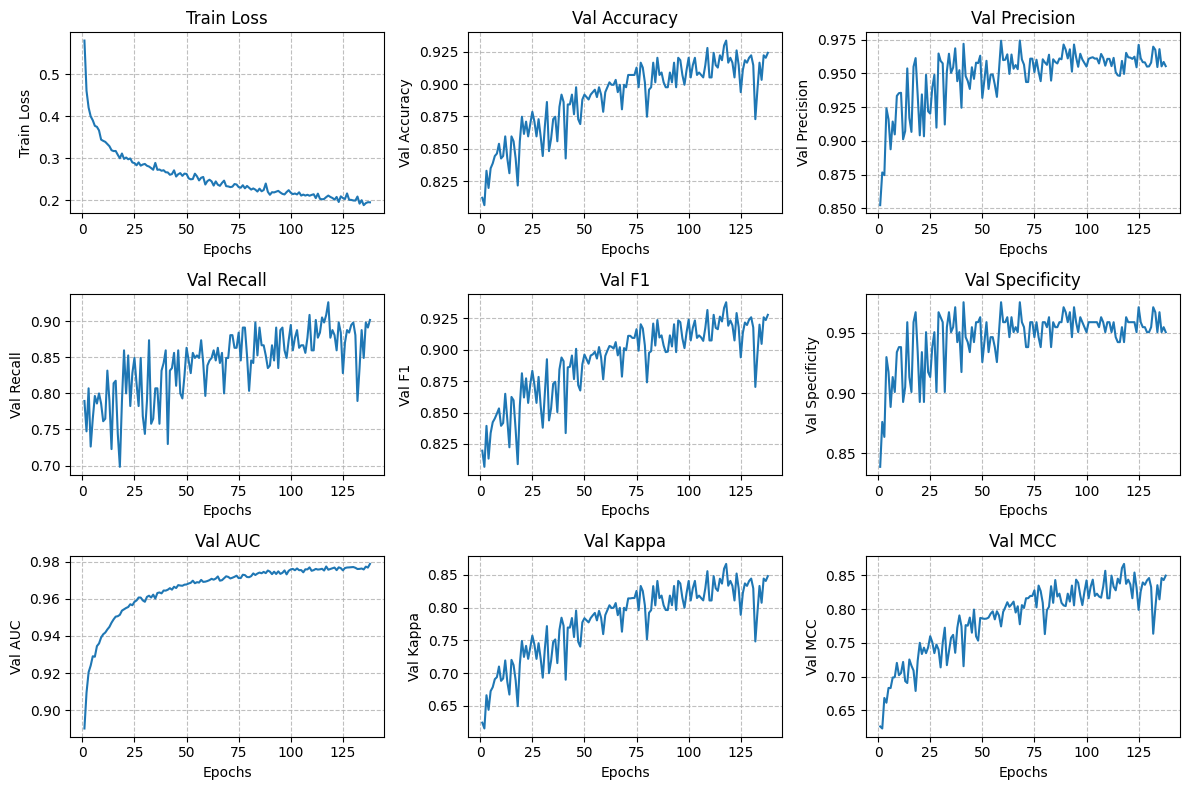

In [ ]:
metrics_to_plot = [
    "Train Loss",
    "Val Accuracy",
    "Val Precision",
    "Val Recall",
    "Val F1",
    "Val Specificity",
    "Val AUC",
    "Val Kappa",
    "Val MCC"
]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 8))
axes = axes.flatten()

for i, metric in enumerate(metrics_to_plot):
    axes[i].plot(ache_logs["Epoch"], ache_logs[metric], label=metric)
    axes[i].set_title(metric)
    axes[i].set_xlabel("Epochs")
    axes[i].set_ylabel(metric)
    axes[i].grid(True, linestyle='--', alpha=0.8)

plt.tight_layout()
plt.show()